# EDA – antifakenewscenter.com scam posts

Exploratory look at `data/antifakenews_scam.csv` (built by `scrapping.ipynb`): which Thai
organizations scammers use, whether the scam reaches people by **call** or **text**, and how the
scams change over time.

`ORG`, `Channel` and the scam themes below come from keyword rules, so treat the numbers as a first
pass, not ground truth. Every chart is followed by the table it was drawn from.

## Key findings

1. **The organizations scammers use most** are ปปง. (AMLO, 35 posts), กรมการขนส่งทางบก (34),
   ธนาคารออมสิน (GSB, 30), ก.ล.ต. (22) and การไฟฟ้าส่วนภูมิภาค (PEA, 21). Most are government
   departments (36% of posts) or state enterprises (20%); commercial banks are only 5%.
2. **Text dominates and calls are fading.** 47 of 362 posts (13%) are call scams. The call share fell
   from 36% in 2021 and 22% in 2023 to 7% in 2025 and 6% in 2026, while the number of posts doubled.
3. **Calls cluster in specific scams.** Bills/meters (4 of 7), handouts (4 of 6) and parcels (4 of 6)
   are mostly calls, and กระทรวงการคลัง is impersonated by phone in 3 of 5 posts. Driving-licence,
   investment and lottery scams never use calls in this data.
4. **Scam themes come in waves.** Loan scams peaked in 2022–23. Fake driving-licence pages appeared
   in 2025 (22 posts, all text; 32 of the 37 licence posts name กรมการขนส่งทางบก). "Money recovery" scams, which
   target people who were already scammed, start in 2024; 15 of those 27 posts name ปปง. Jobs scams return in 2026.
5. **#อาชญากรรมออนไลน์ is a 2026 tag** (44% of 2026 posts, 4 posts before). Splitting the data by
   hashtag is effectively splitting it by time.
6. **Coverage gaps.** 74 posts (20%) name no listed organization, mostly private companies, and 163
   titles match none of the 12 themes, so both keyword lists can be extended.

**Ideas for next steps:** label ORG/Channel with an LLM on a sample to measure how accurate the keyword
rules are; add private companies (SET-listed companies, telcos, e-commerce) to the organization list;
use the themes as features or stratification for the scam classifier; split train/test by date, not
at random, because the scam mix shifts each year.

In [1]:
import re

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

df = pd.read_csv("data/antifakenews_scam.csv", encoding="utf-8-sig", parse_dates=["date"],
                 date_format="%d/%m/%Y", keep_default_na=False)
orgs = pd.read_csv("data/thai_organizations.csv", encoding="utf-8-sig", keep_default_na=False).set_index("name_th")

# text and call keep the same colour in every chart
TEXT, CALL = "#2a78d6", "#eb6834"
CHANNELS = {"text": TEXT, "call": CALL}
SINGLE = "#6250d6"                      # one-series charts, so blue only ever means "text"
HIGHLIGHT, OTHER = "#1baf7a", "#c3c2b7"  # emphasis: one category in colour, the rest grey
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

# fonts with Thai glyphs (Windows, Linux, macOS); only list installed ones, or matplotlib warns about each missing one
installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONTS = [f for f in ["Leelawadee UI", "Tahoma", "Noto Sans Thai", "Thonburi"] if f in installed]

plt.rcParams.update({
    "font.family": [*THAI_FONTS, "sans-serif"],
    "font.size": 10,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.titlepad": 12, "legend.frameon": False,
})

last_day = df["date"].max()
YEAR_LABEL = lambda y: f"{y}\n(to {last_day:%d %b})" if y == last_day.year else str(y)  # current year is partial
print(f"{len(df)} posts from {df['date'].min():%d/%m/%Y} to {last_day:%d/%m/%Y}")


def stacked_barh(ax, table, labels):
    """Text/call bars, largest at the top, with the total at the end of each bar."""
    y = list(range(len(table)))[::-1]
    left = 0
    for channel, color in CHANNELS.items():
        ax.barh(y, table[channel], left=left, color=color, height=0.62, label=channel.capitalize(),
                edgecolor=SURFACE, linewidth=1.5)
        left = left + table[channel]
    for yi, total in zip(y, left):
        ax.text(total + table["total"].max() * 0.01, yi, str(total), va="center", fontsize=9, color=INK_2)
    ax.set_yticks(y, labels)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, table["total"].max() * 1.12)
    ax.legend(loc="lower right")

362 posts from 02/08/2020 to 17/10/2026


## 1. Which organizations do scammers use?

A post counts once for every organization in its `ORG` (3 posts name two). The bar colour shows how
the scam reached people.

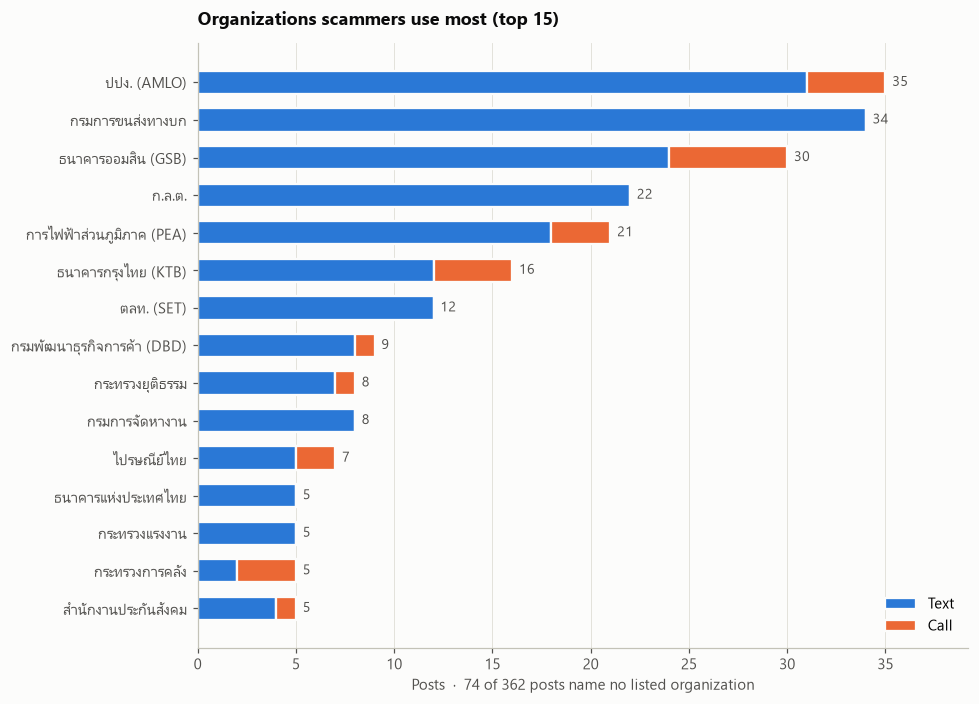

Channel,label,text,call,total
org,,,,
สำนักงานป้องกันและปราบปรามการฟอกเงิน,ปปง. (AMLO),31,4,35
กรมการขนส่งทางบก,กรมการขนส่งทางบก,34,0,34
ธนาคารออมสิน,ธนาคารออมสิน (GSB),24,6,30
สำนักงานคณะกรรมการกำกับหลักทรัพย์และตลาดหลักทรัพย์,ก.ล.ต.,22,0,22
การไฟฟ้าส่วนภูมิภาค,การไฟฟ้าส่วนภูมิภาค (PEA),18,3,21
ธนาคารกรุงไทย,ธนาคารกรุงไทย (KTB),12,4,16
ตลาดหลักทรัพย์แห่งประเทศไทย,ตลท. (SET),12,0,12
กรมพัฒนาธุรกิจการค้า,กรมพัฒนาธุรกิจการค้า (DBD),8,1,9
กระทรวงยุติธรรม,กระทรวงยุติธรรม,7,1,8


In [2]:
def short_name(name):
    """Chart label: the name without บริษัท/จำกัด, or its Thai abbreviation when the name is long."""
    base = re.sub(r"^บริษัท\s*|\s*จำกัด|\s*\(มหาชน\)", "", name).strip()
    abbr_th = orgs.at[name, "abbr_th"].split("|")[0].removeprefix("สำนักงาน").strip()
    abbr_en = orgs.at[name, "abbr_en"].split("|")[0]
    label = base if len(base) <= 24 or not abbr_th else abbr_th
    return f"{label} ({abbr_en})" if abbr_en else label


mentions = df.assign(org=df["ORG"].str.split(", ")).explode("org", ignore_index=True).query("org != ''")
by_org = pd.crosstab(mentions["org"], mentions["Channel"]).reindex(columns=list(CHANNELS), fill_value=0)
by_org["total"] = by_org.sum(axis=1)
top = by_org.sort_values("total", ascending=False).head(15)
top.insert(0, "label", [short_name(n) for n in top.index])

fig, ax = plt.subplots(figsize=(9, 6.5))
stacked_barh(ax, top, top["label"])
ax.set_xlabel(f"Posts  ·  {(df['ORG'] == '').sum()} of {len(df)} posts name no listed organization")
ax.set_title("Organizations scammers use most (top 15)")
fig.tight_layout()
plt.show()
top

## 2. Call or text?

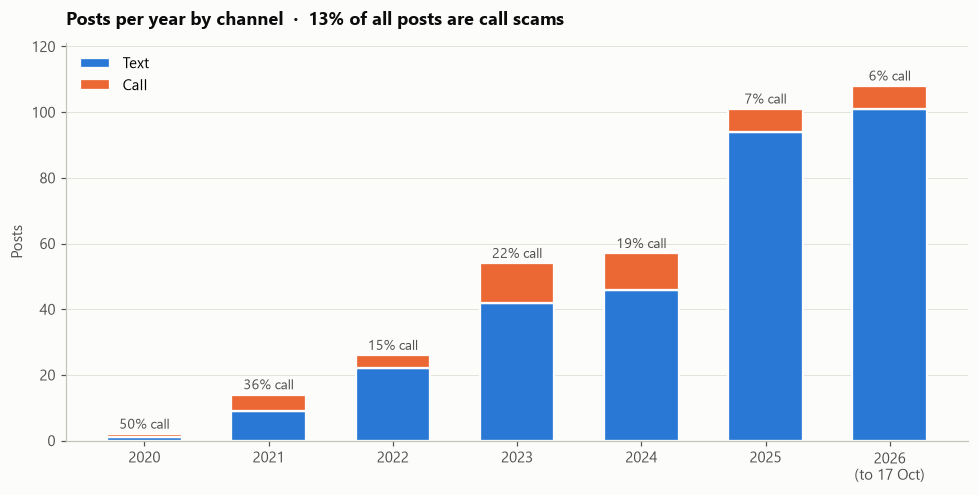

Channel,text,call,total,call share
date,,,,
2020,1,1,2,0.50
2021,9,5,14,0.36
2022,22,4,26,0.15
2023,42,12,54,0.22
2024,46,11,57,0.19
2025,94,7,101,0.07
2026,101,7,108,0.06


In [3]:
by_year = pd.crosstab(df["date"].dt.year, df["Channel"]).reindex(columns=list(CHANNELS), fill_value=0)
by_year["total"] = by_year.sum(axis=1)
by_year["call share"] = (by_year["call"] / by_year["total"]).round(2)

fig, ax = plt.subplots(figsize=(9, 4.6))
x = [YEAR_LABEL(y) for y in by_year.index]
bottom = 0
for channel, color in CHANNELS.items():
    ax.bar(x, by_year[channel], bottom=bottom, color=color, width=0.6, label=channel.capitalize(),
           edgecolor=SURFACE, linewidth=1.5)
    bottom = bottom + by_year[channel]
for xi, total, share in zip(x, by_year["total"], by_year["call share"]):
    ax.text(xi, total + by_year["total"].max() * 0.015, f"{share:.0%} call", ha="center", fontsize=9, color=INK_2)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Posts")
ax.set_ylim(0, by_year["total"].max() * 1.12)
overall = (df["Channel"] == "call").mean()
ax.set_title(f"Posts per year by channel  ·  {overall:.0%} of all posts are call scams")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
by_year

## 3. What are the scams about?

Themes are keyword groups matched in the **title** (Thai keywords in the `THEMES` table below). A post
can have several themes, and some have none.

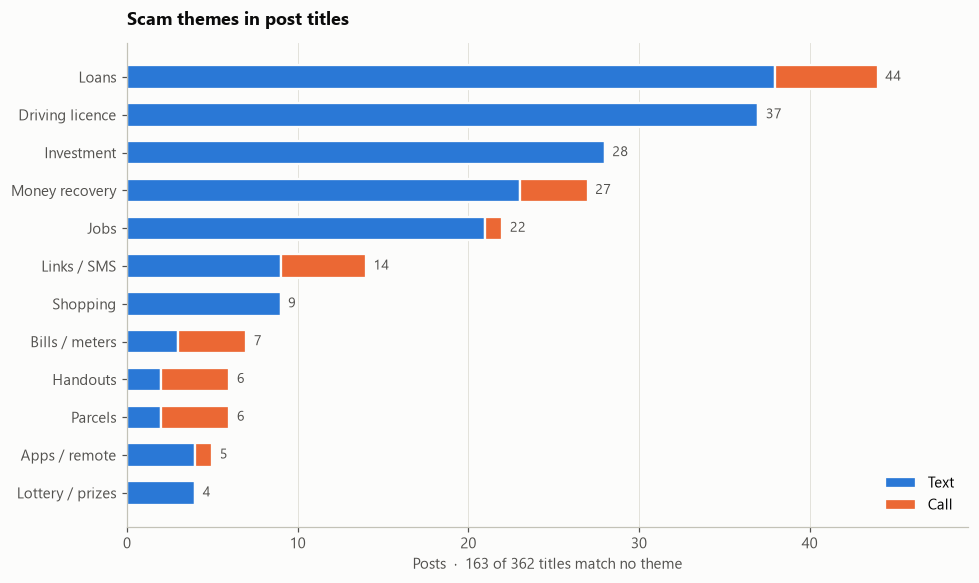

,text,call,total
Loans,38,6,44
Driving licence,37,0,37
Investment,28,0,28
Money recovery,23,4,27
Jobs,21,1,22
Links / SMS,9,5,14
Shopping,9,0,9
Bills / meters,3,4,7
Handouts,2,4,6
Parcels,2,4,6


In [4]:
THEMES = {
    "Loans": r"สินเชื่อ|กู้เงิน|เงินกู้|ปล่อยกู้",
    "Driving licence": r"ใบขับขี่",
    "Investment": r"ลงทุน|หุ้น|เทรด|คริปโต",
    "Money recovery": r"เงินคืน|ติดตามเงิน|ทวงเงิน|กู้คืน",
    "Jobs": r"สมัครงาน|รับสมัคร|ทำงาน|รายได้เสริม|งานออนไลน์",
    "Links / SMS": r"ลิงก์|ลิงค์|SMS",
    "Shopping": r"ซื้อ|ขายของ|สั่งซื้อ|ร้านค้า",
    "Bills / meters": r"ค้างชำระ|ค่าไฟ|ค่าน้ำ|มิเตอร์",
    "Handouts": r"เงินเยียวยา|แจกเงิน|รับสิทธิ์|สวัสดิการ|เงินช่วยเหลือ",
    "Parcels": r"พัสดุ",
    "Lottery / prizes": r"สลาก|หวย|รางวัล",
    "Apps / remote": r"แอปฯ|แอปพลิเคชัน|ติดตั้งแอป|รีโมท|Remote",
}
in_theme = pd.DataFrame({theme: df["title"].str.contains(p) for theme, p in THEMES.items()})
by_theme = pd.DataFrame({ch: in_theme[df["Channel"] == ch].sum() for ch in CHANNELS})
by_theme["total"] = by_theme.sum(axis=1)
by_theme = by_theme.sort_values("total", ascending=False)
no_theme = (~in_theme.any(axis=1)).sum()

fig, ax = plt.subplots(figsize=(9, 5.4))
stacked_barh(ax, by_theme, by_theme.index)
ax.set_xlabel(f"Posts  ·  {no_theme} of {len(df)} titles match no theme")
ax.set_title("Scam themes in post titles")
fig.tight_layout()
plt.show()
by_theme

## 4. How the themes changed over time

The seven biggest themes, by year. Darker = more posts; blank = none.

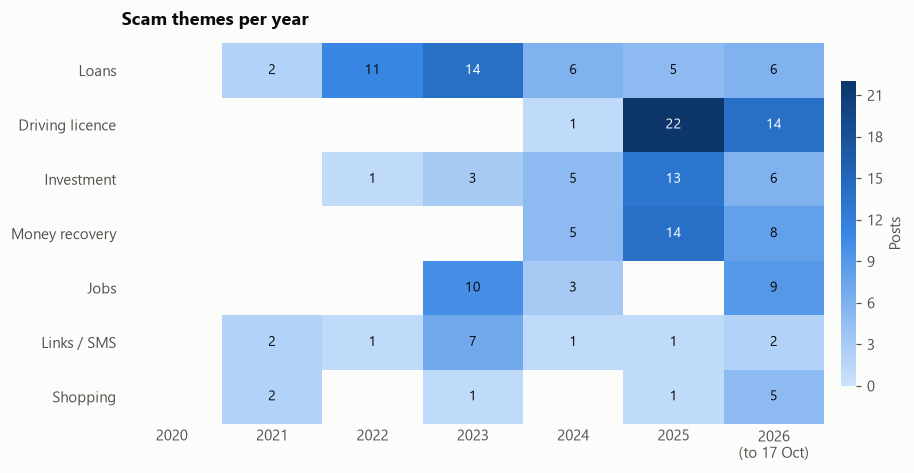

date,2020,2021,2022,2023,2024,2025,2026
Loans,0,2,11,14,6,5,6
Driving licence,0,0,0,0,1,22,14
Investment,0,0,1,3,5,13,6
Money recovery,0,0,0,0,5,14,8
Jobs,0,0,0,10,3,0,9
Links / SMS,0,2,1,7,1,1,2
Shopping,0,2,0,1,0,1,5


In [5]:
per_year = in_theme.groupby(df["date"].dt.year).sum().T.loc[by_theme.index[:7]]

fig, ax = plt.subplots(figsize=(9, 4.4))
im = ax.imshow(per_year.where(per_year > 0), cmap=BLUES, aspect="auto", vmin=0)
for (i, j), n in pd.DataFrame(per_year.values).stack().items():
    if n:
        ax.text(j, i, n, ha="center", va="center", fontsize=9,
                color="white" if n > per_year.values.max() * 0.5 else INK)
ax.set_xticks(range(per_year.shape[1]), [YEAR_LABEL(y) for y in per_year.columns])
ax.set_yticks(range(per_year.shape[0]), per_year.index)
ax.grid(False)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
bar = fig.colorbar(im, ax=ax, label="Posts", shrink=0.8, pad=0.02)
bar.outline.set_visible(False)
bar.locator = MaxNLocator(integer=True)
bar.update_ticks()
ax.set_title("Scam themes per year")
fig.tight_layout()
plt.show()
per_year

## 5. The site's new hashtag

Every post here is tagged #มิจฉาชีพ plus #ข่าวปลอม and/or #อาชญากรรมออนไลน์. The second tag is
recent, so a model trained on one tag sees a different slice of time than the other.

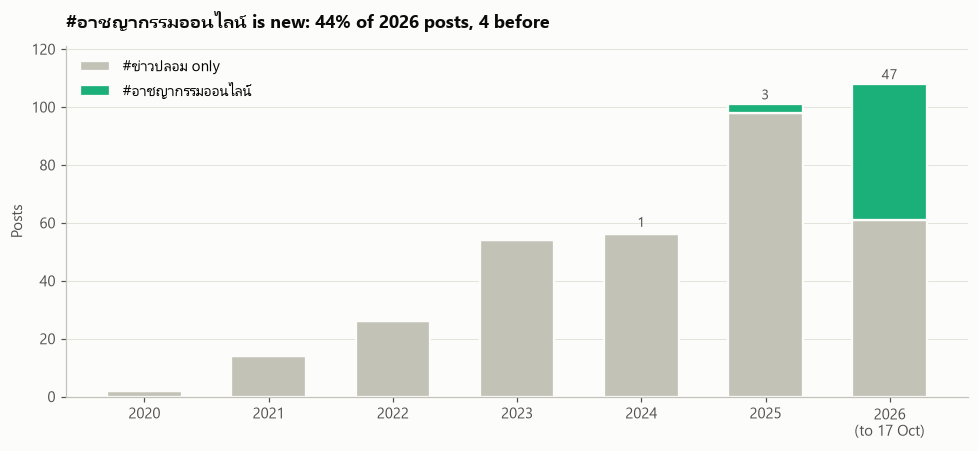

,#ข่าวปลอม only,#อาชญากรรมออนไลน์
date,,
2020,2,0
2021,14,0
2022,26,0
2023,54,0
2024,56,1
2025,98,3
2026,61,47


In [6]:
online = df["hashtag"].str.contains("อาชญากรรมออนไลน์")
by_tag = pd.crosstab(df["date"].dt.year, online).reindex(columns=[False, True], fill_value=0)
by_tag.columns = ["#ข่าวปลอม only", "#อาชญากรรมออนไลน์"]
latest = by_tag.loc[last_day.year]

fig, ax = plt.subplots(figsize=(9, 4.2))
x = [YEAR_LABEL(y) for y in by_tag.index]
ax.bar(x, by_tag["#ข่าวปลอม only"], color=OTHER, width=0.6, label="#ข่าวปลอม only", edgecolor=SURFACE, linewidth=1.5)
ax.bar(x, by_tag["#อาชญากรรมออนไลน์"], bottom=by_tag["#ข่าวปลอม only"], color=HIGHLIGHT, width=0.6,
       label="#อาชญากรรมออนไลน์", edgecolor=SURFACE, linewidth=1.5)
for xi, n, total in zip(x, by_tag["#อาชญากรรมออนไลน์"], by_tag.sum(axis=1)):
    if n:
        ax.text(xi, total + by_tag.sum(axis=1).max() * 0.015, str(n), ha="center", fontsize=9, color=INK_2)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Posts")
ax.set_ylim(0, by_tag.sum(axis=1).max() * 1.12)
ax.set_title(f"#อาชญากรรมออนไลน์ is new: {latest.iloc[1] / latest.sum():.0%} of {last_day.year} posts, "
             f"{by_tag['#อาชญากรรมออนไลน์'].drop(last_day.year).sum()} before")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
by_tag

## 6. What kind of organization?

The type of the first organization in each post's `ORG`, from the DGA classification.

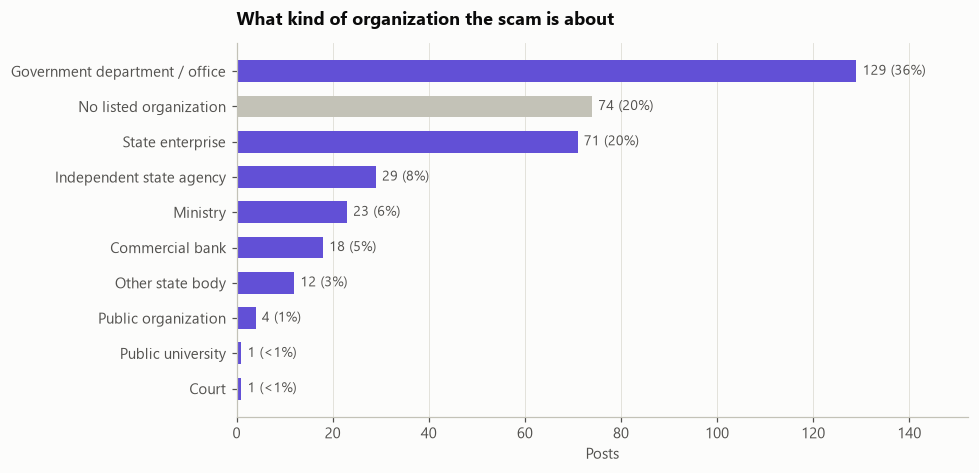

,posts
ORG,
Government department / office,129
No listed organization,74
State enterprise,71
Independent state agency,29
Ministry,23
Commercial bank,18
Other state body,12
Public organization,4
Public university,1


In [7]:
TYPE_EN = {
    "ส่วนราชการ": "Government department / office",
    "รัฐวิสาหกิจ": "State enterprise",
    "หน่วยงานอิสระของรัฐ": "Independent state agency",
    "กระทรวง": "Ministry",
    "ธนาคาร": "Commercial bank",
    "หน่วยงานอื่นของรัฐ": "Other state body",
    "องค์การมหาชนตามพระราชกฤษฎีกา": "Public organization",
    "หน่วยงานในกำกับหรือองค์การมหาชนตามพระราชบัญญัติ": "Public organization",
    "สถาบันอุดมศึกษาของรัฐ": "Public university",
    "หน่วยงานของศาล": "Court",
}
first_org = df["ORG"].str.split(", ").str[0]
org_type = first_org.map(orgs["type"]).map(TYPE_EN).where(first_org != "", "No listed organization")
type_counts = org_type.value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 4.4))
colors = [OTHER if t == "No listed organization" else SINGLE for t in type_counts.index]
ax.barh(type_counts.index, type_counts, color=colors, height=0.62)
for yi, n in enumerate(type_counts):
    ax.text(n + type_counts.max() * 0.01, yi, f"{n} ({n / len(df):.0%})" if n / len(df) >= 0.005 else f"{n} (<1%)", va="center", fontsize=9, color=INK_2)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, type_counts.max() * 1.18)
ax.set_xlabel("Posts")
ax.set_title("What kind of organization the scam is about")
fig.tight_layout()
plt.show()
type_counts.sort_values(ascending=False).to_frame("posts")